### Wikipedia retrivers

In [17]:
from langchain_community.retrievers import WikipediaRetriever

In [21]:
retriever = WikipediaRetriever(top_k_results=2, lang="en")
# Define your query
query = "the geopolitical history of india and pakistan from the perspective of a chinese"

# Get relevant Wikipedia documents
docs = retriever.invoke(query)

In [ ]:
docs

[Document(metadata={'title': 'India–Pakistan war of 1971', 'summary': "The India–Pakistan war of 1971, also known as the third Indo-Pakistani war, was a military confrontation between India and Pakistan that occurred during the Bangladesh Liberation War in East Pakistan from 3 December 1971 until the Pakistani capitulation in Dhaka on 16 December 1971.  The war began with Pakistan's Operation Chengiz Khan, consisting of preemptive aerial strikes on eight Indian air stations. The strikes led to India declaring war on Pakistan, marking their entry into the war for East Pakistan's independence, on the side of Bengali nationalist forces. India's entry expanded the existing conflict with Indian and Pakistani forces engaging on both the eastern and western fronts.\nThirteen days after the war started, India achieved a clear advantage, and the Eastern Command of the Pakistan military signed the instrument of surrender on 16 December 1971 in Dhaka, marking the formation of East Pakistan as the

In [ ]:
# Print retrieved content
for i, doc in enumerate(docs):
    print(f"\n--- Result {i+1} ---")
    print(f"Content:\n{doc.page_content}...")  # truncate for display


--- Result 1 ---
Content:
The India–Pakistan war of 1971, also known as the third Indo-Pakistani war, was a military confrontation between India and Pakistan that occurred during the Bangladesh Liberation War in East Pakistan from 3 December 1971 until the Pakistani capitulation in Dhaka on 16 December 1971.  The war began with Pakistan's Operation Chengiz Khan, consisting of preemptive aerial strikes on eight Indian air stations. The strikes led to India declaring war on Pakistan, marking their entry into the war for East Pakistan's independence, on the side of Bengali nationalist forces. India's entry expanded the existing conflict with Indian and Pakistani forces engaging on both the eastern and western fronts.
Thirteen days after the war started, India achieved a clear advantage, and the Eastern Command of the Pakistan military signed the instrument of surrender on 16 December 1971 in Dhaka, marking the formation of East Pakistan as the new nation of Bangladesh. Approximately 93,0

### Vector store retrivers

In [1]:
from langchain_community.vectorstores import Chroma
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_core.documents import Document

C:\Users\Admin\AppData\Local\Temp\ipykernel_14200\2758231571.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import Chroma


In [3]:
# Step 1: Your source documents
doc = [
    Document("LangChain helps developers build LLM applications easily."),
    Document("Chroma is a vector database optimized for LLM-based search."),
    Document("Embeddings convert text into high-dimensional vectors."),
    Document("OpenAI provides powerful embedding models."),
]

In [4]:
# Step 2: Initialize embedding model
embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001"
)

# Step 3: Create Chroma vector store in memory
vector_store = Chroma.from_documents(
    documents=doc,
    persist_directory='./my_retriver',
    collection_name='simple',
    embedding=embeddings,
)

In [8]:
retriever = vector_store.as_retriever(
    search_kwargs={"k": 2}
)

query = "What is Chroma used for?"
results = retriever.invoke(query)

In [9]:
for i, doc in enumerate(results):
    print(f"\n--- Result {i+1} ---")
    print(doc.page_content)


--- Result 1 ---
Chroma is a vector database optimized for LLM-based search.

--- Result 2 ---
LangChain helps developers build LLM applications easily.


### MMR (picks diverse results)

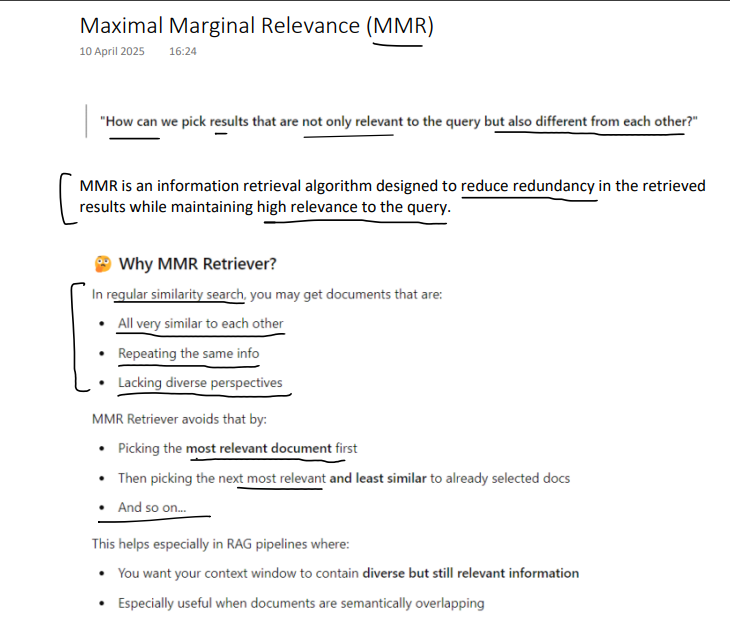

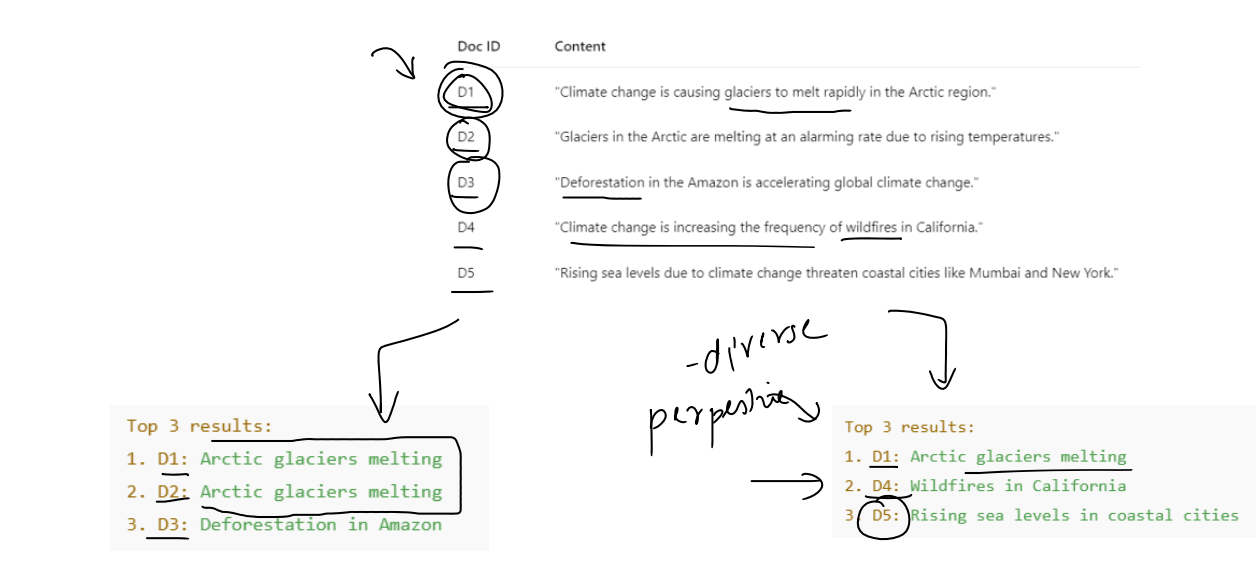

In [19]:
from langchain_core.documents import Document
# Sample documents
docsMMR = [
    Document(page_content="LangChain makes it easy to work with LLMs."),
    Document(page_content="LangChain is used to build LLM based applications."),
    Document(page_content="Chroma is used to store and search document embeddings."),
    Document(page_content="Embeddings are vector representations of text."),
    Document(page_content="MMR helps you get diverse results when doing similarity search."),
    Document(page_content="LangChain supports Chroma, FAISS, Pinecone, and more."),
]

In [20]:
from langchain_community.vectorstores import FAISS
from langchain_google_genai import GoogleGenerativeAIEmbeddings

# Step 2: Initialize embedding model
embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001"
)

# Step 3: Create Chroma vector store in memory
vectorstore = FAISS.from_documents(
    documents=docsMMR,
    embedding=embeddings,
)

C:\Users\Admin\AppData\Local\Temp\ipykernel_17452\4225269711.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [21]:
# Enable MMR in the retriever
retriever = vectorstore.as_retriever(
    search_type="mmr",                   # <-- This enables MMR
    search_kwargs={"k": 3, "lambda_mult": 0.5}  # k = top results, lambda_mult = relevance-diversity balance
)

In [22]:
query = "What is langchain?"
results = retriever.invoke(query)

In [23]:
for i, doc in enumerate(results):
    print(f"\n--- Result {i+1} ---")
    print(doc.page_content)


--- Result 1 ---
LangChain is used to build LLM based applications.

--- Result 2 ---
MMR helps you get diverse results when doing similarity search.

--- Result 3 ---
LangChain supports Chroma, FAISS, Pinecone, and more.


diverse outputs de rha h 


### Multiquery Retriever(finding all the pssble meaning of user query ==> finding soln for all query(retrival for all) ==> combining the soln and deduplicates them)

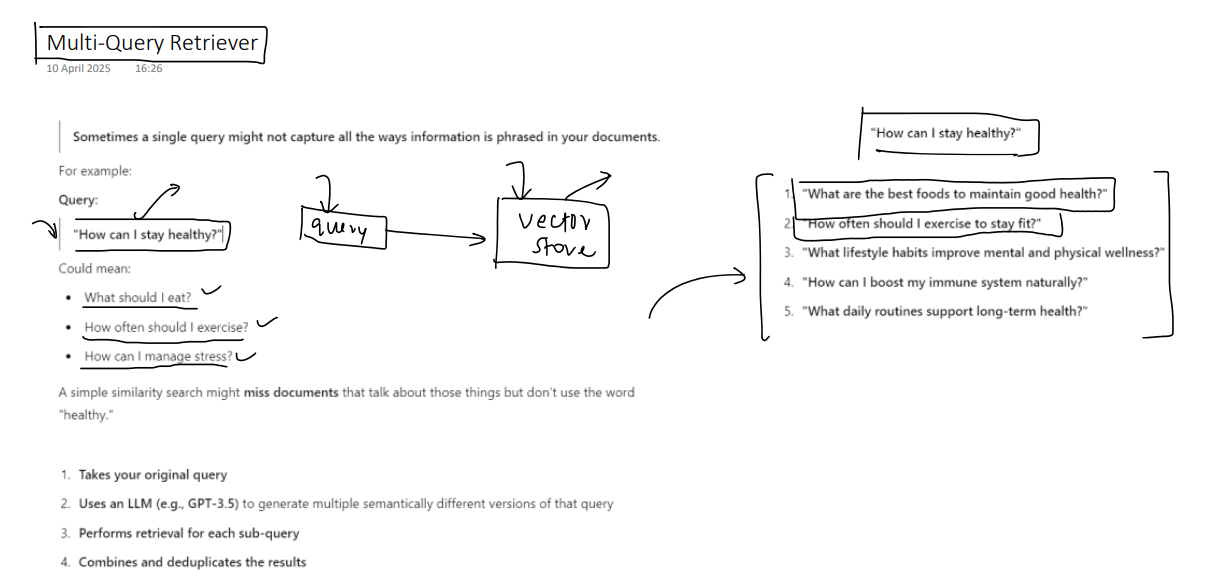

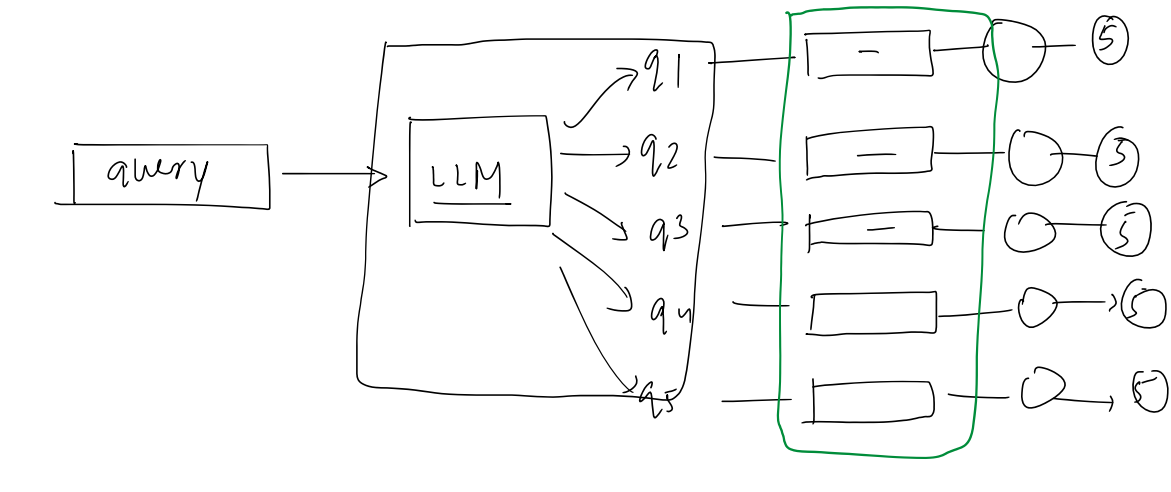

In [26]:
from langchain_community.vectorstores import FAISS
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_core.documents import Document
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_classic.retrievers import MultiQueryRetriever

In [27]:
# Relevant health & wellness documents
all_docs = [
    Document(page_content="Regular walking boosts heart health and can reduce symptoms of depression.", metadata={"source": "H1"}),
    Document(page_content="Consuming leafy greens and fruits helps detox the body and improve longevity.", metadata={"source": "H2"}),
    Document(page_content="Deep sleep is crucial for cellular repair and emotional regulation.", metadata={"source": "H3"}),
    Document(page_content="Mindfulness and controlled breathing lower cortisol and improve mental clarity.", metadata={"source": "H4"}),
    Document(page_content="Drinking sufficient water throughout the day helps maintain metabolism and energy.", metadata={"source": "H5"}),
    Document(page_content="The solar energy system in modern homes helps balance electricity demand.", metadata={"source": "I1"}),
    Document(page_content="Python balances readability with power, making it a popular system design language.", metadata={"source": "I2"}),
    Document(page_content="Photosynthesis enables plants to produce energy by converting sunlight.", metadata={"source": "I3"}),
    Document(page_content="The 2022 FIFA World Cup was held in Qatar and drew global energy and excitement.", metadata={"source": "I4"}),
    Document(page_content="Black holes bend spacetime and store immense gravitational energy.", metadata={"source": "I5"}),
]

In [28]:
# Initialize embeddings model
embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001"
)

# Create FAISS vector store
vectorstore = FAISS.from_documents(documents=all_docs, embedding=embeddings)

In [29]:
# Create retrievers
similarity_retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 5})

In [30]:
multiquery_retriever = MultiQueryRetriever.from_llm(
    retriever=vectorstore.as_retriever(search_kwargs={"k": 5}),
    llm=ChatGoogleGenerativeAI(model="gemini-3.6-flash")
)

In [31]:
# Query
query = "How to improve energy levels and maintain balance?"

In [32]:
# Retrieve results
similarity_results = similarity_retriever.invoke(query)#simple retriver
multiquery_results= multiquery_retriever.invoke(query)#multiquery one

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


In [33]:
for i, doc in enumerate(similarity_results):
    print(f"\n--- Result {i+1} ---")
    print(doc.page_content)

print("*"*150)

for i, doc in enumerate(multiquery_results):
    print(f"\n--- Result {i+1} ---")
    print(doc.page_content)


--- Result 1 ---
Drinking sufficient water throughout the day helps maintain metabolism and energy.

--- Result 2 ---
The solar energy system in modern homes helps balance electricity demand.

--- Result 3 ---
Mindfulness and controlled breathing lower cortisol and improve mental clarity.

--- Result 4 ---
Consuming leafy greens and fruits helps detox the body and improve longevity.

--- Result 5 ---
Regular walking boosts heart health and can reduce symptoms of depression.
******************************************************************************************************************************************************

--- Result 1 ---
Drinking sufficient water throughout the day helps maintain metabolism and energy.

--- Result 2 ---
Consuming leafy greens and fruits helps detox the body and improve longevity.

--- Result 3 ---
Regular walking boosts heart health and can reduce symptoms of depression.

--- Result 4 ---
Mindfulness and controlled breathing lower cortisol and impro

### ContextualCompressionRetriever(retrives the short, compressed and relevant output )

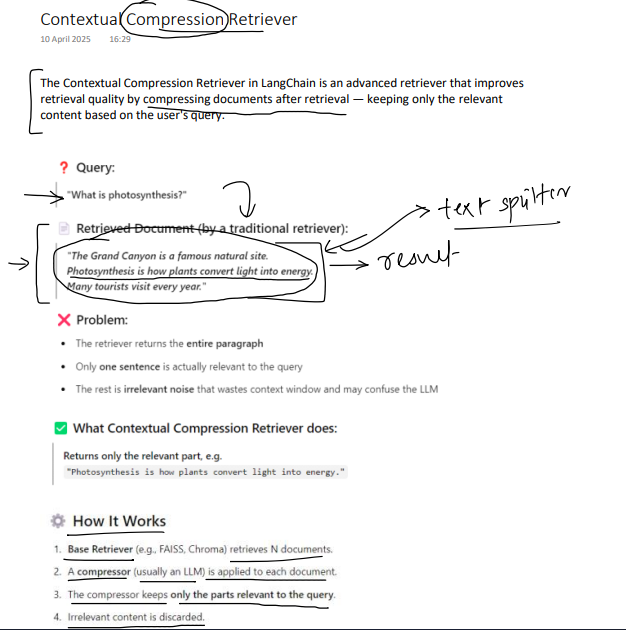

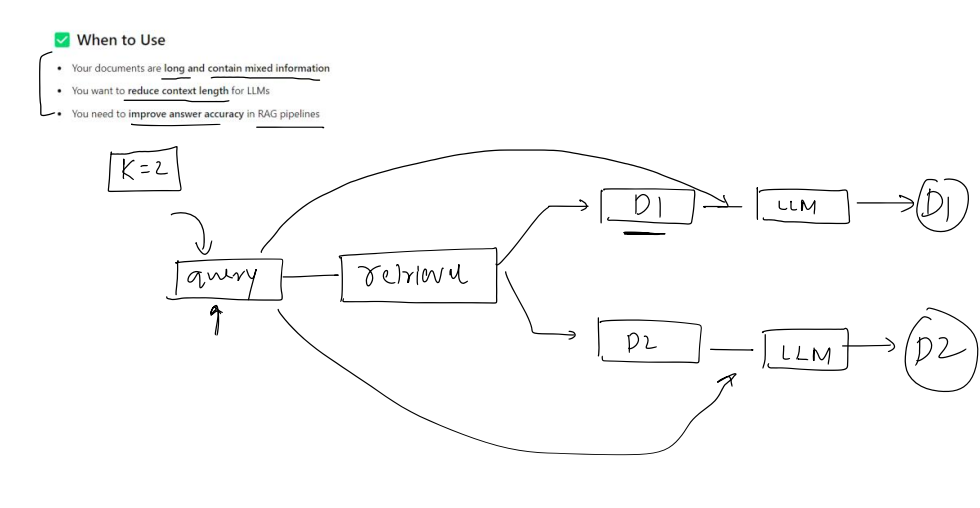

In [38]:
from langchain_community.vectorstores import FAISS
from langchain_google_genai import (
    GoogleGenerativeAIEmbeddings,
    ChatGoogleGenerativeAI
)
from langchain_classic.retrievers import ContextualCompressionRetriever
from langchain_classic.retrievers.document_compressors import LLMChainExtractor
from langchain_core.documents import Document

In [39]:
# Recreate the document objects from the previous data
docsCCR = [
    Document(page_content=(
        """The Grand Canyon is one of the most visited natural wonders in the world.
        Photosynthesis is the process by which green plants convert sunlight into energy.
        Millions of tourists travel to see it every year. The rocks date back millions of years."""
    ), metadata={"source": "Doc1"}),

    Document(page_content=(
        """In medieval Europe, castles were built primarily for defense.
        The chlorophyll in plant cells captures sunlight during photosynthesis.
        Knights wore armor made of metal. Siege weapons were often used to breach castle walls."""
    ), metadata={"source": "Doc2"}),

    Document(page_content=(
        """Basketball was invented by Dr. James Naismith in the late 19th century.
        It was originally played with a soccer ball and peach baskets. NBA is now a global league."""
    ), metadata={"source": "Doc3"}),

    Document(page_content=(
        """The history of cinema began in the late 1800s. Silent films were the earliest form.
        Thomas Edison was among the pioneers. Photosynthesis does not occur in animal cells.
        Modern filmmaking involves complex CGI and sound design."""
    ), metadata={"source": "Doc4"})
]

In [41]:
embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001"
)
vectorstore = FAISS.from_documents(docsCCR, embeddings)

In [42]:
base_retriever = vectorstore.as_retriever(search_kwargs={"k": 5})

In [43]:
# Set up the compressor using an LLM
llm = ChatGoogleGenerativeAI(model="gemini-3.6-flash")
compressor = LLMChainExtractor.from_llm(llm)

In [44]:
# Create the contextual compression retriever
compression_retriever = ContextualCompressionRetriever(
    base_retriever=base_retriever,
    base_compressor=compressor
)

In [45]:
# Query the retriever
query = "What is photosynthesis?"
compressed_results = compression_retriever.invoke(query)

In [47]:
for i, doc in enumerate(compressed_results):
    print(f"\n--- Result {i+1} ---")
    print(doc.page_content)



--- Result 1 ---
Photosynthesis is the process by which green plants convert sunlight into energy.


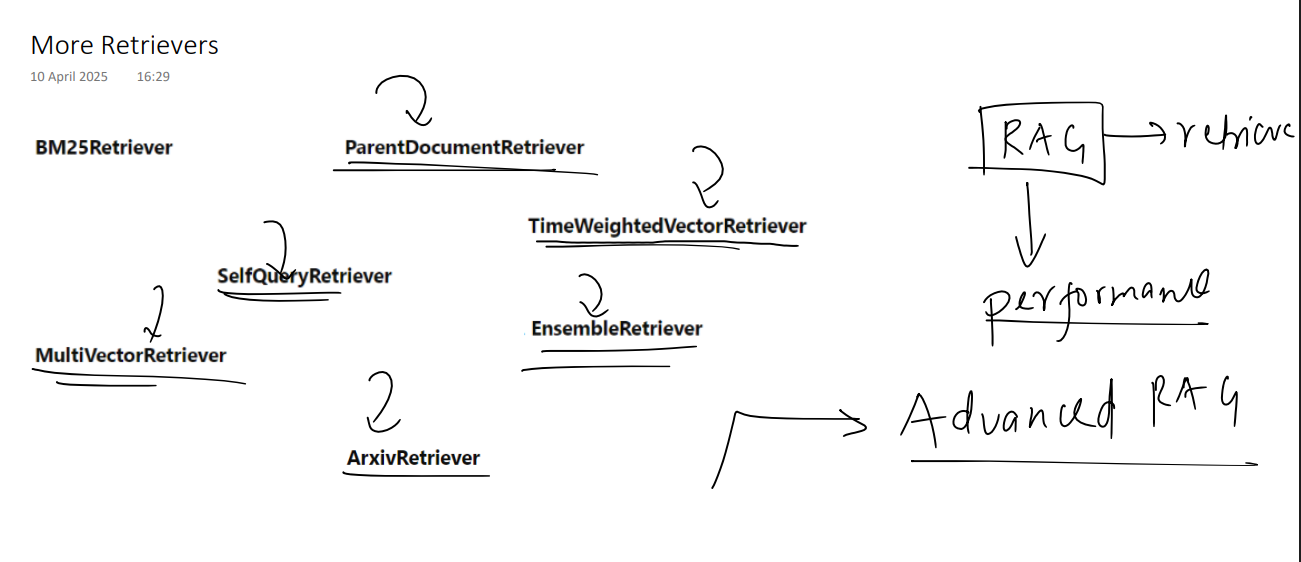